In [13]:
import pandas as pd
import matplotlib.pyplot as plt

In [73]:
data = pd.read_csv("study_hours_gpa_practice.csv")
data

,study_hours,gpa
0,1.3,2.57
1,1.5,1.55
2,1.7,2.99
3,1.8,1.27
4,1.9,2.01
...,...,...
245,38.8,4.00
246,38.9,3.88
247,38.9,3.55
248,39.0,3.37


In [74]:
df = pd.DataFrame(data)
df

,study_hours,gpa
0,1.3,2.57
1,1.5,1.55
2,1.7,2.99
3,1.8,1.27
4,1.9,2.01
...,...,...
245,38.8,4.00
246,38.9,3.88
247,38.9,3.55
248,39.0,3.37


In [75]:
df

,study_hours,gpa
0,1.3,2.57
1,1.5,1.55
2,1.7,2.99
3,1.8,1.27
4,1.9,2.01
...,...,...
245,38.8,4.00
246,38.9,3.88
247,38.9,3.55
248,39.0,3.37


In [76]:
df.shape

(250, 2)

In [77]:
df.isnull().value_counts()

study_hours  gpa  
False        False    250
Name: count, dtype: int64

In [78]:
df.drop_duplicates()

,study_hours,gpa
0,1.3,2.57
1,1.5,1.55
2,1.7,2.99
3,1.8,1.27
4,1.9,2.01
...,...,...
245,38.8,4.00
246,38.9,3.88
247,38.9,3.55
248,39.0,3.37


In [79]:
df.shape

(250, 2)

In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   study_hours  250 non-null    float64
 1   gpa          250 non-null    float64
dtypes: float64(2)
memory usage: 4.0 KB


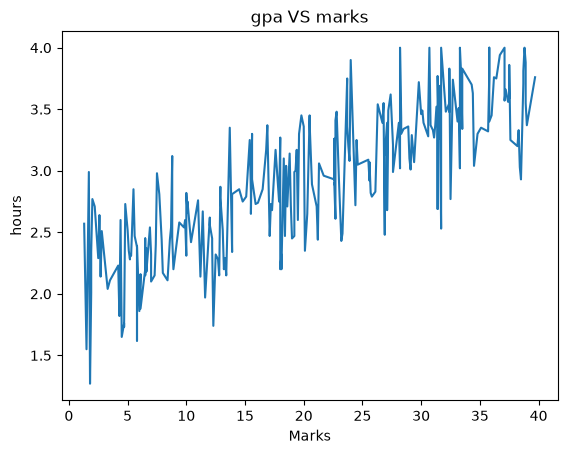

In [81]:
plt.plot(df["study_hours"], df["gpa"])
plt.xlabel("Marks")
plt.ylabel("hours")
plt.title("gpa VS marks")
plt.show()

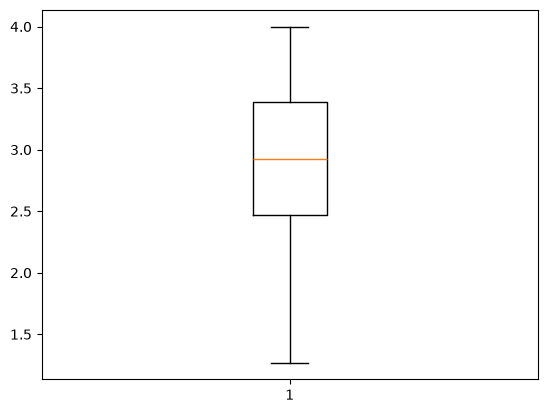

In [82]:
plt.boxplot(df["gpa"])
plt.show()

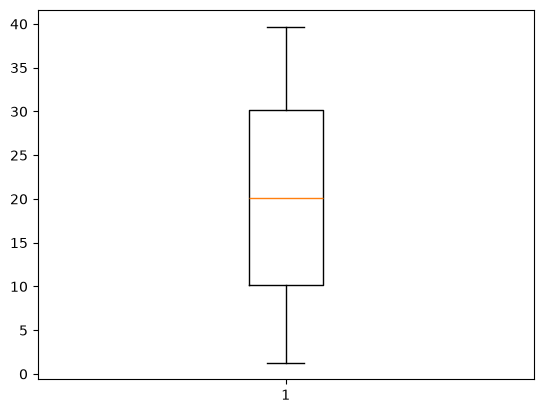

In [83]:
plt.boxplot(df["study_hours"])
plt.show() 

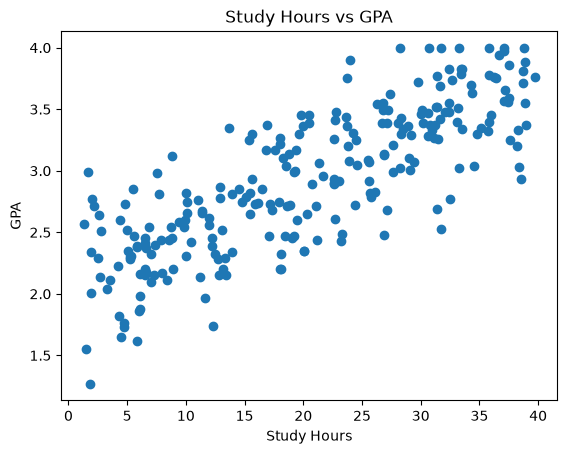

In [84]:
plt.scatter(df["study_hours"], df["gpa"])
plt.xlabel("Study Hours")
plt.ylabel("GPA")
plt.title("Study Hours vs GPA")
plt.show()

In [85]:
Q1 = df["gpa"].quantile(0.25)
Q3 = df["gpa"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["gpa"] < lower) |
    (df["gpa"] > upper)
]

print(outliers)

Empty DataFrame
Columns: [study_hours, gpa]
Index: []


In [86]:
cols = ["gpa", "study_hours"]

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[
        (df[col] >= lower) &
        (df[col] <= upper)
    ]

In [87]:
df

,study_hours,gpa
0,1.3,2.57
1,1.5,1.55
2,1.7,2.99
3,1.8,1.27
4,1.9,2.01
...,...,...
245,38.8,4.00
246,38.9,3.88
247,38.9,3.55
248,39.0,3.37


In [88]:
df.shape

(250, 2)

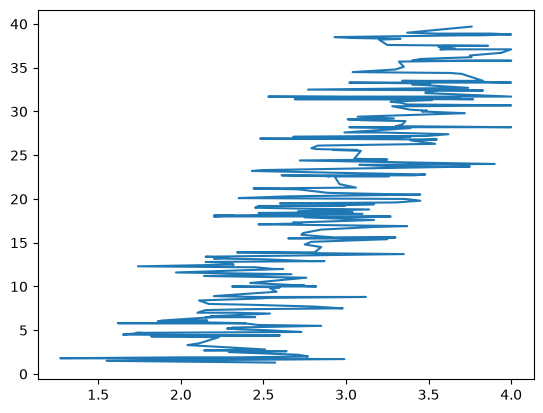

In [89]:
plt.plot(df["gpa"], df["study_hours"])
plt.show()

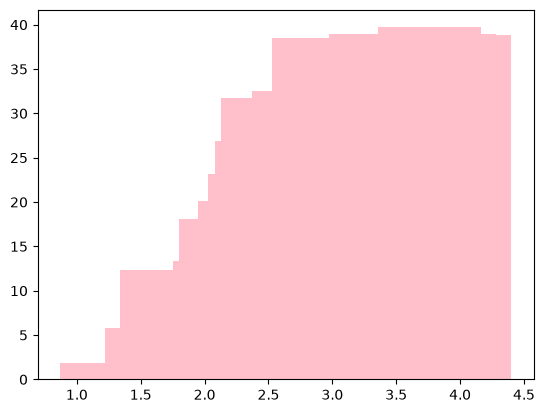

In [103]:
plt.bar(df["gpa"], df["study_hours"], color="pink")
plt.show()

In [91]:
X = df[["study_hours"]]
y = df["gpa"]

In [92]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [93]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [94]:
### What is test_size=0.2?
### It determines how much of your dataset is reserved for testing the model.

"""
random_state is used to make the random train-test split reproducible. 
It ensures that we get the same training and testing samples when we run the code 
again with the same settings.
"""

'\nrandom_state is used to make the random train-test split reproducible. \nIt ensures that we get the same training and testing samples when we run the code \nagain with the same settings.\n'

In [95]:
model = LinearRegression()

In [96]:
model.fit(X_train, y_train)

"""
This is the key step!
- X_train contains the study hours.
- y_train contains the actual GPA values.
- .fit() learns a relationship between study hours and GPA.
"""

'\nThis is the key step!\n- X_train contains the study hours.\n- y_train contains the actual GPA values.\n- .fit() learns a relationship between study hours and GPA.\n'

In [97]:
y_pred = model.predict(X_test)

In [98]:
print("Predicted GPA:", y_pred)
print("Actual GPA:", y_test.values)

Predicted GPA: [3.05652633 2.15708049 2.78499551 2.49649401 2.86136355 3.30684381
 3.4044252  3.33654249 2.1825365  2.83590754 3.41291054 3.49352125
 3.66322801 3.69716936 2.55589138 3.59110264 3.39593986 2.25466188
 3.27290246 2.2928459  3.72262538 2.27163255 2.87409156 2.56437672
 3.27290246 2.38618462 2.44982465 2.18677917 2.31830191 2.89954758
 3.41291054 2.33102992 3.04804099 3.53170527 2.29708857 2.85712089
 2.27163255 3.4044252  3.30260114 3.17956374 2.89106224 2.7722675
 2.84015021 3.34502783 3.56140395 2.25890454 3.07773968 2.58134739
 3.26441712 2.3480006 ]
Actual GPA: [2.43 2.77 3.17 2.82 2.71 3.01 2.69 3.72 2.64 3.27 3.69 3.34 3.59 3.33
 2.67 3.78 3.37 1.82 3.3  2.3  3.55 1.73 2.72 1.97 3.43 2.4  2.2  2.14
 2.39 2.6  3.42 1.98 2.92 3.63 2.31 3.04 1.76 3.52 3.1  2.83 3.   2.85
 2.2  3.46 3.35 2.6  3.36 2.62 3.39 2.15]


In [99]:
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error:", mae)

Mean Absolute Error: 0.24908729529002271


In [100]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

Mean Squared Error: 0.09821649314609102


In [101]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)
print("R² Score:", r2)

R² Score: 0.6932262322548026


In [ ]:
#“I evaluated my model using MAE, MSE, RMSE, and R². MAE measures the average absolute prediction error, 
# while R² measures how much variation in the target variable is explained by the model.”

Accuracy: 91.29308951027605 %
